In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.model_selection import learning_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve

from astroML.classification import GMMBayes
from astroML.utils import split_samples, completeness_contamination

### Time to get your hands dirty. SDSS Galaxies vs quasars

*(exam guidelines available [here](https://github.com/dgerosa/astrostatistics_bicocca_2026/blob/main/exams.md))*

We're now going to classify galaxy vs quasars in the Sloan Digital Sky Survey. 

This is one of the most famous example of machine-learning classification in astronomy. For some recent work see e.g. 
- *Identifying galaxies, quasars, and stars with machine learning: A new catalogue of classifications for 111 million SDSS sources without spectra* Clarke et al (2019) [arXiv:1909.10963](https://arxiv.org/abs/1909.10963)
- *Quasar and galaxy classification in Gaia Data Release 2* Bailer-Jones et al (2019) [arXiv:1910.05255](https://arxiv.org/abs/1910.05255)

Some figures from the second paper:


#### Data

The dataset is at `solutions/galaxyquasar.csv`. I have extracted it myself from the SDSS database using the SQL query reported [here](https://www.astroml.org/_modules/astroML/datasets/sdss_galaxy_colors.html#fetch_sdss_galaxy_colors)

(If you've never used [SQL](https://en.wikipedia.org/wiki/SQL) and want to learn something new in computing, it's very powerful)

#### Tasks

- Create arrays for the $(u-g)$, $(g-r)$, $(r-i)$, and $(i-z)$ colors. Also create an array with the class labels where galaxy=$0$ and quasar=$1$. 
- Classify the dataset against the target label.
- Try some of the classification methods we've seen so far and evaluate the performance using the ROC curve.
- Remember to split the dataset into training and validation...

#### Ideas
- Try using different colors (a subset of them first, than all together). Which is the most important feature?
- What are the colors that better satisfy or invalidate the "Naive" assumption of independence between the attributes?


### Reading 

In [2]:
df_quasar = pd.read_csv("galaxyquasar.csv")
print(df_quasar)

              u         g         r         i         z   class        z1  \
0      18.97213  18.53676  18.58280  18.34936  18.29215     QSO  0.522819   
1      19.24592  17.47646  16.47817  16.04472  15.68851  GALAXY  0.122846   
2      19.43536  17.70268  16.91565  16.58327  16.39128  GALAXY  0.000000   
3      19.31626  18.18312  17.39591  16.94549  16.65395  GALAXY  0.147435   
4      19.28828  19.11188  18.88937  18.80013  18.49183     QSO  2.011455   
...         ...       ...       ...       ...       ...     ...       ...   
49995  19.37295  18.12382  17.39886  16.98503  16.70585  GALAXY  0.113016   
49996  18.52021  16.88262  16.03280  15.56884  15.22454  GALAXY  0.085063   
49997  18.62718  17.30876  16.87371  16.62399  16.42296  GALAXY  0.054429   
49998  19.55140  18.27711  17.62101  17.21947  17.03347  GALAXY  0.112571   
49999  18.80772  17.75751  17.40500  17.21650  17.12295  GALAXY  0.043652   

           zerr  
0      0.000155  
1      0.000028  
2      0.000000  
3  

In [3]:
df_quasar["u-g"] = df_quasar["u"] - df_quasar["g"]
df_quasar["g-r"] = df_quasar["g"] - df_quasar["r"]
df_quasar["r-i"] = df_quasar["r"] - df_quasar["i"]
df_quasar["i-z"] = df_quasar["i"] - df_quasar["z"]
df_quasar["labels"] = df_quasar["class"].map({"GALAXY": 0, "QSO": 1})
print(df_quasar)

              u         g         r         i         z   class        z1  \
0      18.97213  18.53676  18.58280  18.34936  18.29215     QSO  0.522819   
1      19.24592  17.47646  16.47817  16.04472  15.68851  GALAXY  0.122846   
2      19.43536  17.70268  16.91565  16.58327  16.39128  GALAXY  0.000000   
3      19.31626  18.18312  17.39591  16.94549  16.65395  GALAXY  0.147435   
4      19.28828  19.11188  18.88937  18.80013  18.49183     QSO  2.011455   
...         ...       ...       ...       ...       ...     ...       ...   
49995  19.37295  18.12382  17.39886  16.98503  16.70585  GALAXY  0.113016   
49996  18.52021  16.88262  16.03280  15.56884  15.22454  GALAXY  0.085063   
49997  18.62718  17.30876  16.87371  16.62399  16.42296  GALAXY  0.054429   
49998  19.55140  18.27711  17.62101  17.21947  17.03347  GALAXY  0.112571   
49999  18.80772  17.75751  17.40500  17.21650  17.12295  GALAXY  0.043652   

           zerr      u-g      g-r      r-i      i-z  labels  
0      0.0001

### $1_{\rm{st}}$ Visualization

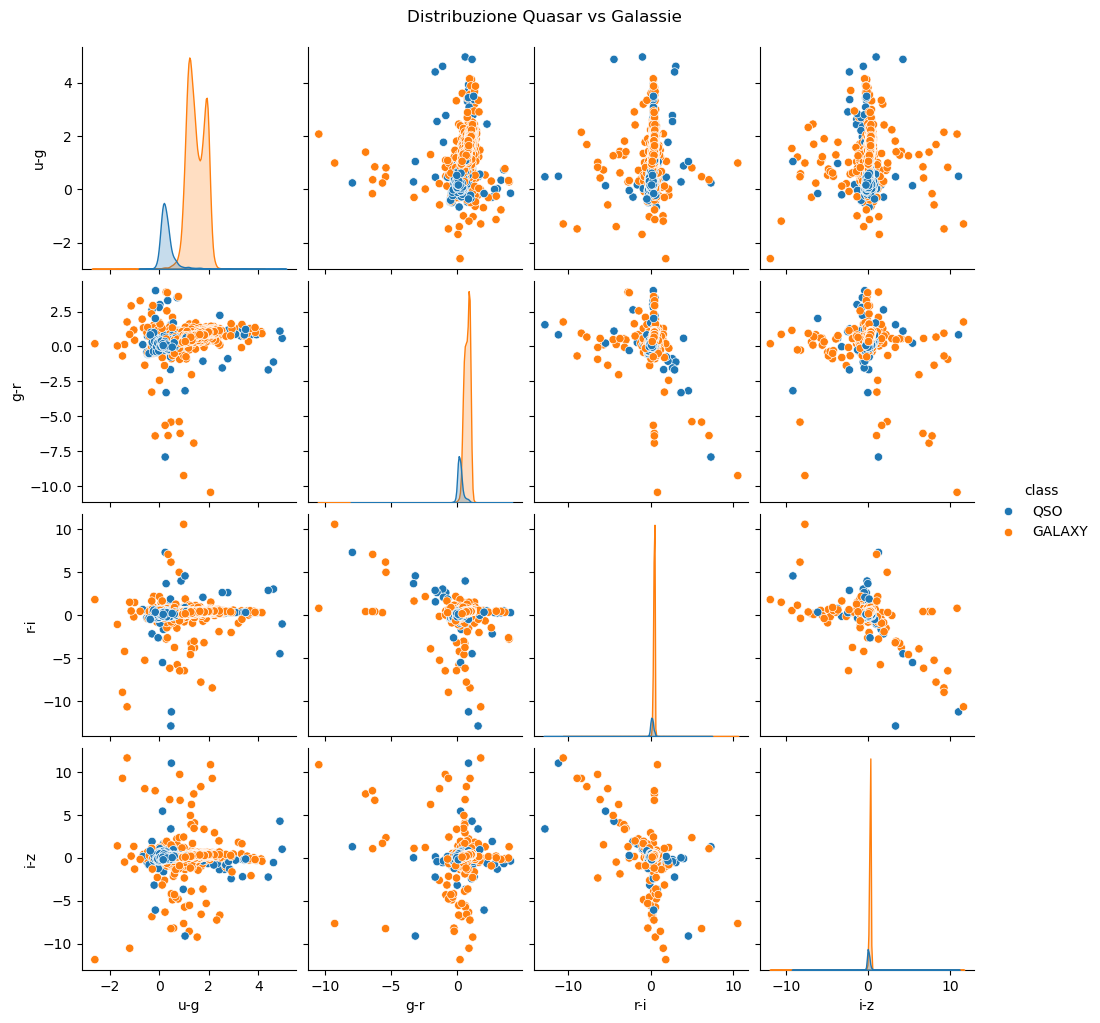

In [8]:
sns.pairplot(df_quasar[["u-g", "g-r", "r-i", "i-z", "class"]], hue="class")
plt.suptitle('Distribuzione Quasar vs Galassie', y=1.02)
plt.show()

In [14]:
matrice_correlazione = df_quasar[["u-g", "g-r", "r-i", "i-z"]].corr()

print(matrice_correlazione)

          u-g       g-r       r-i       i-z
u-g  1.000000  0.803315  0.469237  0.360335
g-r  0.803315  1.000000  0.347712  0.318454
r-i  0.469237  0.347712  1.000000 -0.158128
i-z  0.360335  0.318454 -0.158128  1.000000


## Classification

- Gaussian Naive Bayes
- Linear Discriminant Analysis
- Quadratic Discriminant Analysis
- GMM Bayes Classifier
- K-Nearest Neighbor Classifier

### Gaussian Naive Bayes


In [12]:
X = df_quasar[["u-g", "g-r", "r-i", "i-z"]].values
y = df_quasar["labels"].values                

(X_train, X_test), (y_train, y_test) = split_samples(X, y, [0.75, 0.25],
                                                     random_state=0)

gnb = GaussianNB()
gnb.fit(X_train.reshape(-1, 1), y_train)

y_pred_gnb = gnb.predict(X_test.reshape(-1, 1))

ValueError: Found input variables with inconsistent numbers of samples: [150000, 37500]

#### Shit

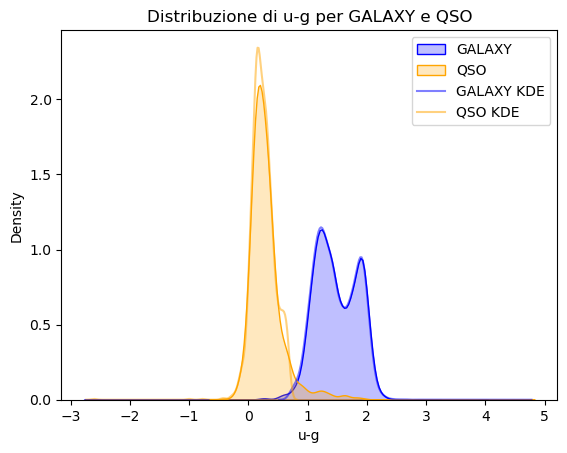

In [ ]:
sns.kdeplot(X_test[y_test == 0], color='blue', label='GALAXY', fill=True)
sns.kdeplot(X_test[y_test == 1], color='orange', label='QSO', fill=True)
sns.kdeplot(X_test[y_pred_gnb == 0], color='blue', label='GALAXY KDE', fill=False, alpha=0.5)
sns.kdeplot(X_test[y_pred_gnb == 1], color='orange', label='QSO KDE', fill=False, alpha=0.5)
plt.xlabel('u-g')
plt.ylabel('Density')
plt.title('Distribuzione di u-g per GALAXY e QSO')
plt.legend()
plt.show()

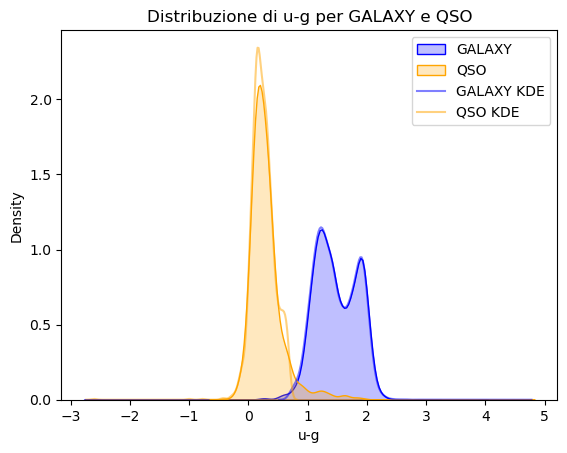

In [ ]:
X = df_quasar[["u-g", "g-r", "r-i", "i-z"]].values 
y = df_quasar["labels"].values                     

(X_train, X_test), (y_train, y_test) = split_samples(X, y, [0.75, 0.25],
                                                     random_state=0)

y_pred_gnb = pd.DataFrame()
labels = ["u-g", "g-r", "r-i", "i-z"] 
gnb = GaussianNB()
for i in range(X_train.shape[1]):
    gnb.fit(X_train[:,i].reshape(-1, 1), y_train)
    y_pred_gnb[i] = gnb.predict(X_test[:,i].reshape(-1, 1))

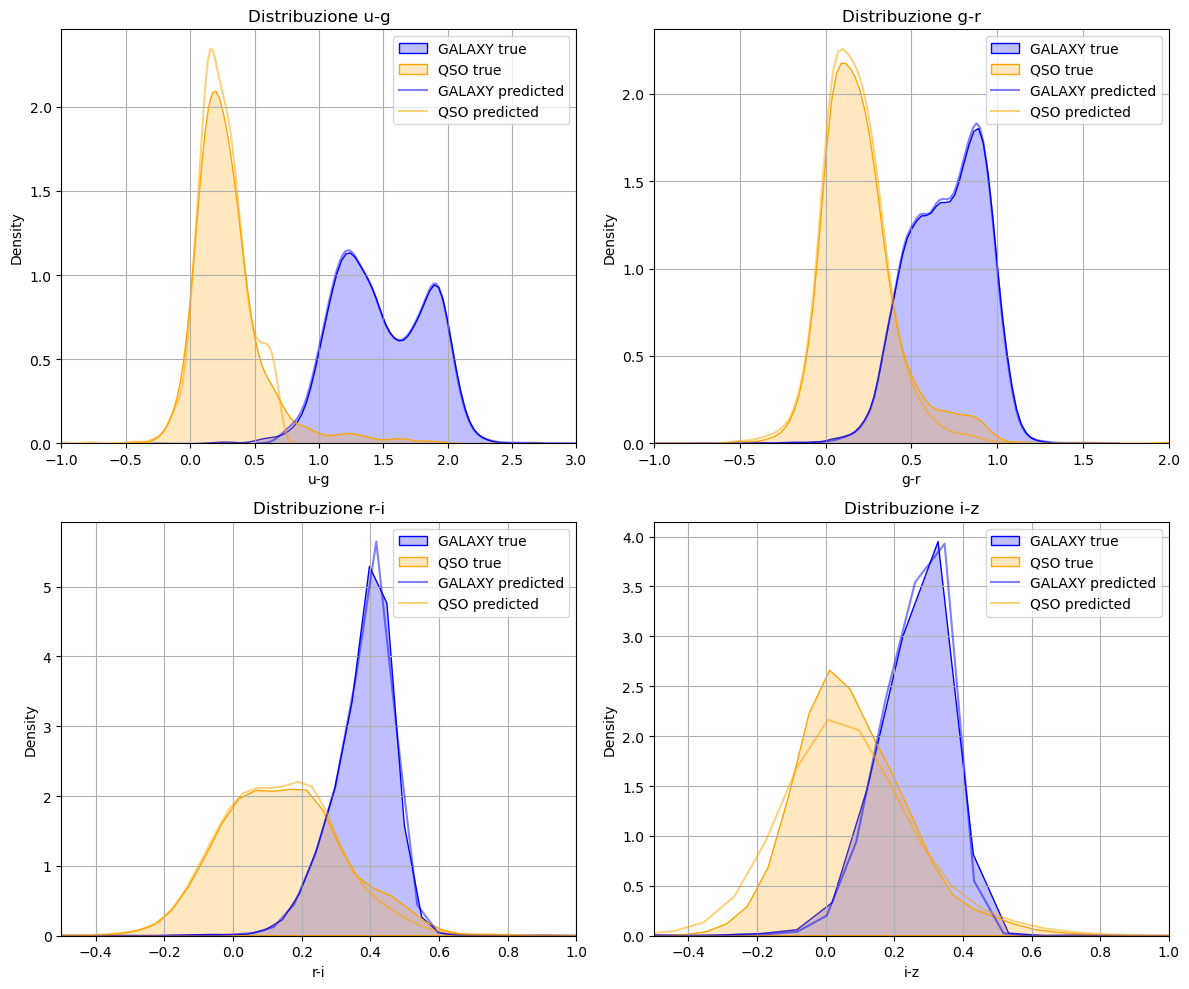

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ax = axes.flatten()
xlim = [[-1, 3], [-1, 2], [-0.5, 1], [-0.5, 1]]

for i in range(4):
    sns.kdeplot(X_test[y_test == 0][:,i], color='blue', ax = ax[i], label='GALAXY true', fill=True)
    sns.kdeplot(X_test[y_test == 1][:,i], color='orange', ax = ax[i], label='QSO true', fill=True)
    sns.kdeplot(X_test[y_pred_gnb[0] == 0][:,i], color='blue', ax = ax[i], label='GALAXY predicted', fill=False, alpha=0.5)
    sns.kdeplot(X_test[y_pred_gnb[0] == 1][:,i], color='orange', ax = ax[i], label='QSO predicted', fill=False, alpha=0.5)
    ax[i].set_title(f'Distribuzione {["u-g", "g-r", "r-i", "i-z"][i]}')
    ax[i].set_xlabel(f'{labels[i]}')
    ax[i].set_ylabel('Density')
    ax[i].legend()
    ax[i].grid()
    ax[i].set_xlim(xlim[i])

plt.tight_layout()
plt.show()

### Full comparison

In [4]:
def compute_models(*args):
    names = []
    probs = []
    X_train, y_train, X_test = args[0]
    for classifier, kwargs in args[1:]:
        print(f"Processing classifier: {classifier.__name__}")
        clf = classifier(**kwargs)
        if X_train.ndim == 1:
            X_train = X_train.reshape(-1, 1)
            X_test = X_test.reshape(-1, 1)
        clf.fit(X_train, y_train)
        
        #Note that we are outputing the probabilities [of class 1], not the classes
        y_probs = clf.predict_proba(X_test)[:, 1]

        names.append(classifier.__name__)
        probs.append(y_probs)

    return names, probs

In [5]:
X = df_quasar[["u-g", "g-r", "r-i", "i-z"]].values
y = df_quasar["labels"].values              
colors = ["u-g", "g-r", "r-i", "i-z"]



(X_train, X_test), (y_train, y_test) = split_samples(X, y, [0.75, 0.25],
                                                     random_state=0)



col_probs = []
for i, col in enumerate(colors):
    print(f"Processing column: {colors[i]}")
    set = [X_train[:, i], y_train[:], X_test[:, i]]
    names, probs = compute_models(set, 
                                (GaussianNB, {}),
                                (LDA, {}),
                                (QDA, {}),
                                (KNeighborsClassifier, dict(n_neighbors=10)),
                                (GMMBayes, dict(n_components=3, tol=1E-5,
                                                covariance_type='full')))
    
    col_probs.append(probs)

Processing column: u-g
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes


c:\Users\nicco\anaconda3\Lib\site-packages\sklearn\mixture\_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


Processing column: g-r
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes
Processing column: r-i
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes


c:\Users\nicco\anaconda3\Lib\site-packages\sklearn\mixture\_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


Processing column: i-z
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes


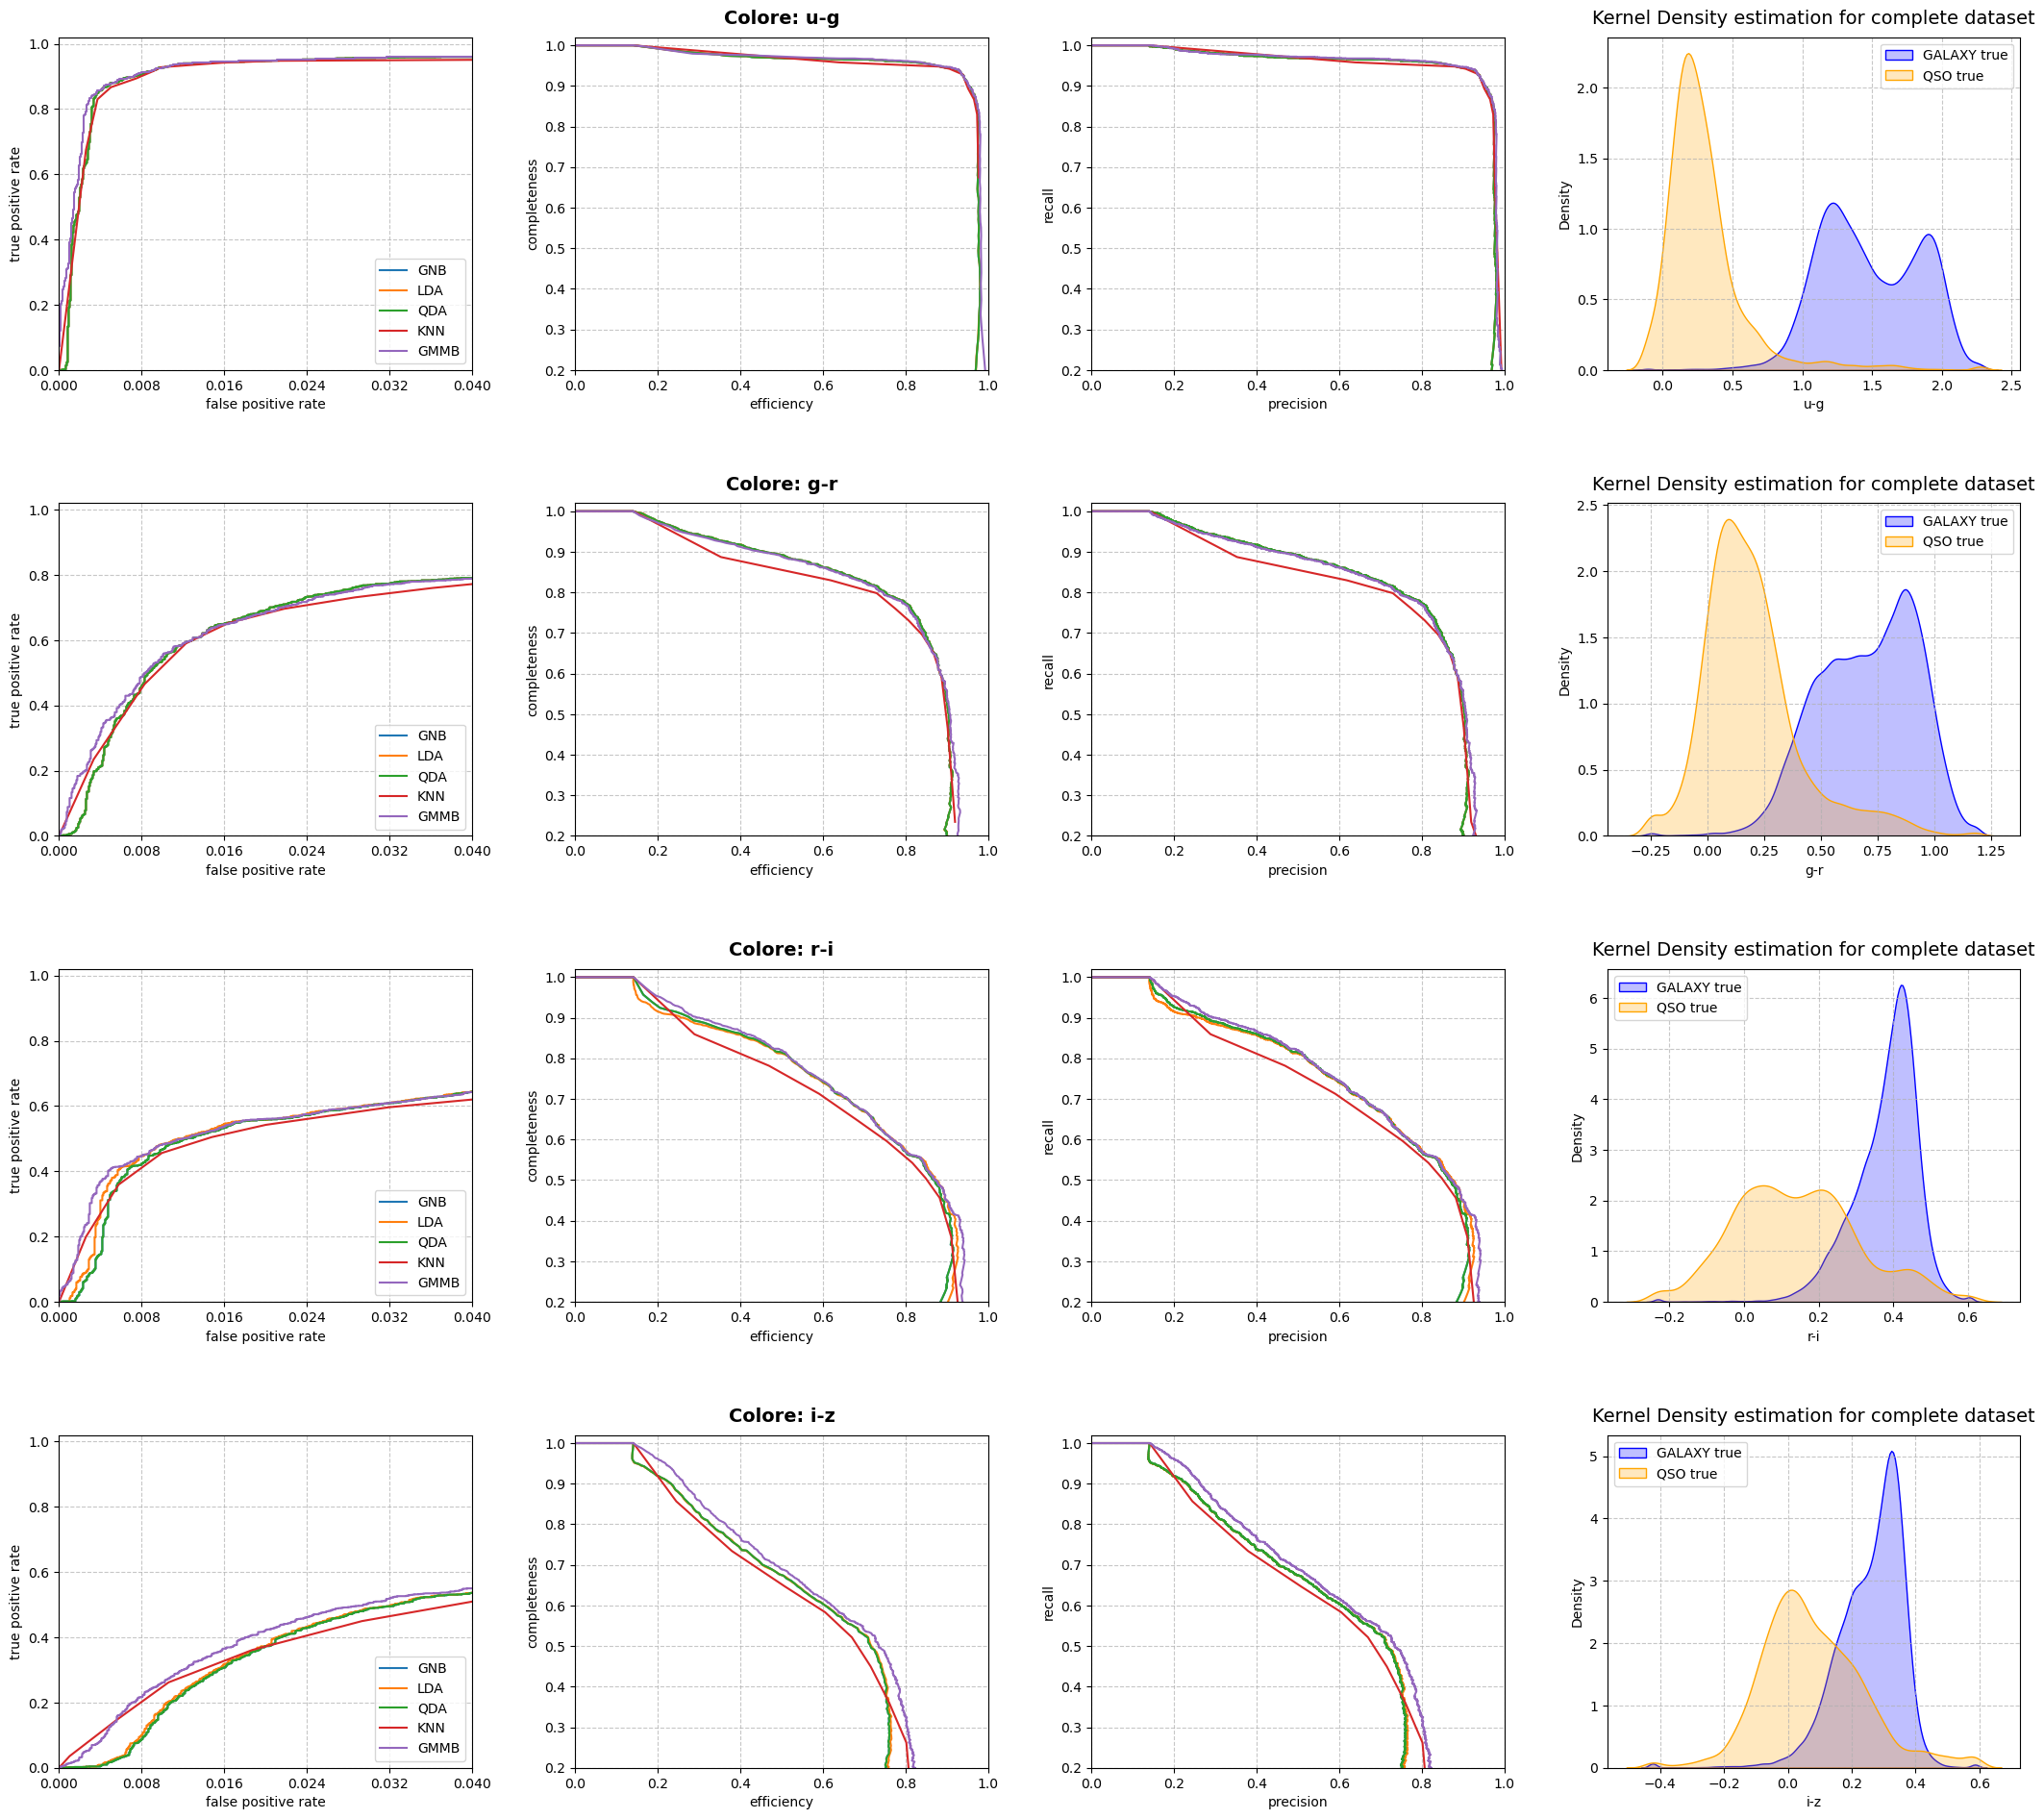

In [6]:
# Plot ROC curves and completeness/efficiency
fig, ax = plt.subplots(4, 4,figsize=(24, 24))

ax = ax.flatten()
fig.subplots_adjust(left=0.1, right=0.95, bottom=0.15, top=0.9, wspace=0.25, hspace=0.4)


labels = dict(GaussianNB='GNB',
              LinearDiscriminantAnalysis='LDA',
              QuadraticDiscriminantAnalysis='QDA',
              KNeighborsClassifier='KNN',
              DecisionTreeClassifier='DT',
              GMMBayes='GMMB',
              LogisticRegression='LR')

thresholds = np.linspace(0, 1, 1001)[:-1]

# iterate through and show results
for i, col in enumerate(colors):
        
    ax1 = 4 * i
    ax2 = ax1 + 1
    ax3 = ax1 + 2
    ax4 = ax1 + 3
        
    for name, y_prob in zip(names, col_probs[i]):
                
        fpr, tpr, thresh = roc_curve(y_test, y_prob)
        precision, recall, thresh2 = precision_recall_curve(y_test, y_prob)

        # add (0, 0) as first point
        fpr = np.concatenate([[0], fpr])
        tpr = np.concatenate([[0], tpr])
        # Here we add (1,0) 
        precision = np.concatenate([[0], precision])
        recall = np.concatenate([[1], recall])
        thresh2 = np.concatenate([[0], thresh2])

        ax[ax1].plot(fpr, tpr, label=labels[name])

        #See note above about astroML vs. sklearn
        #Note that the range of threshhold values here is 0% to 100% (0.0 to 1.0)
        comp = np.zeros_like(thresholds)
        cont = np.zeros_like(thresholds)
        for j, t in enumerate(thresholds):
            y_pred = (y_prob >= t)
            comp[j], cont[j] = completeness_contamination(y_pred, y_test)
        comp = np.concatenate([[1], comp])
        cont = np.concatenate([[1], cont])
        ax[ax2].plot(1 - cont, comp, label=labels[name])
        
        ax[ax3].plot(precision, recall, label=labels[name])

    ax[ax1].set_xlim(0, 0.04)
    ax[ax1].set_ylim(0, 1.02)
    ax[ax1].xaxis.set_major_locator(plt.MaxNLocator(5))
    ax[ax1].set_xlabel('false positive rate')
    ax[ax1].set_ylabel('true positive rate')
    ax[ax1].legend(loc=4)
    ax[ax1].grid(True, linestyle='--', alpha=0.7)

    ax[ax2].set_xlabel('efficiency')
    ax[ax2].set_ylabel('completeness')
    ax[ax2].set_xlim(0, 1.0)
    ax[ax2].set_ylim(0.2, 1.02)
    ax[ax2].set_title(f"Colore: {col}", fontsize=14, fontweight='bold', pad=10)
    ax[ax2].grid(True, linestyle='--', alpha=0.7)

    ax[ax3].set_xlabel('precision')
    ax[ax3].set_ylabel('recall')
    ax[ax3].set_xlim(0, 1.0)
    ax[ax3].set_ylim(0.2, 1.02)
    ax[ax3].grid(True, linestyle='--', alpha=0.7)
    
    #I clip the data to avoid the influence of outliers in the KDE plot
    min_x = np.percentile(X[:, i], 0.25)
    max_x = np.percentile(X[:, i], 99.75)
    X_clipped = np.clip(X[:, i], min_x, max_x)
    
    sns.kdeplot(X_clipped[y == 0], color='blue', ax = ax[ax4], label='GALAXY true', fill=True)
    sns.kdeplot(X_clipped[y == 1], color='orange', ax = ax[ax4], label='QSO true', fill=True)
    ax[ax4].set_title(f"Kernel Density estimation for complete dataset", fontsize=14, pad=10)
    ax[ax4].set_xlabel(f'{col}')
    ax[ax4].set_ylabel('Density')
    ax[ax4].grid(True, linestyle='--', alpha=0.7)
    ax[ax4].legend()

    

    
    

plt.show()

Ho plottato le metriche della classificazione associate ad ogni colore, affiancate dalla kernel density estimation delle due classi di oggetti (sempre per ogni colore) in modo da avere un understanding diretto delle performances. 

### Multicolor
u-g is clearly the better color $\implies$ I'll use it with the other
 

In [7]:
multi_col = [["u-g", "g-r"],["u-g", "r-i"], ["u-g", "i-z"], ["u-g", "g-r", "r-i"], ["u-g", "g-r", "i-z"], ["u-g", "g-r", "r-i", "i-z"]]
multi_label = ["u-g & g-r", "u-g & r-i", "u-g & i-z", "u-g & g-r & r-i", "u-g & g-r & i-z", "All colors"]

multi_col_probs = []
for i, cols in enumerate(multi_col):
    print(f"Processing column: {multi_label[i]}")
    set = [X_train[:, [colors.index(col) for col in cols]], y_train[:], X_test[:, [colors.index(col) for col in cols]]]
    names, probs = compute_models(set, 
                                (GaussianNB, {}),
                                (LDA, {}),
                                (QDA, {}),
                                (KNeighborsClassifier, dict(n_neighbors=10)),
                                (GMMBayes, dict(n_components=3, tol=1E-5,
                                                covariance_type='full')))
    
    multi_col_probs.append(probs)

Processing column: u-g & g-r
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes
Processing column: u-g & r-i
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes
Processing column: u-g & i-z
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes
Processing column: u-g & g-r & r-i
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes
Processing column: u-g & g

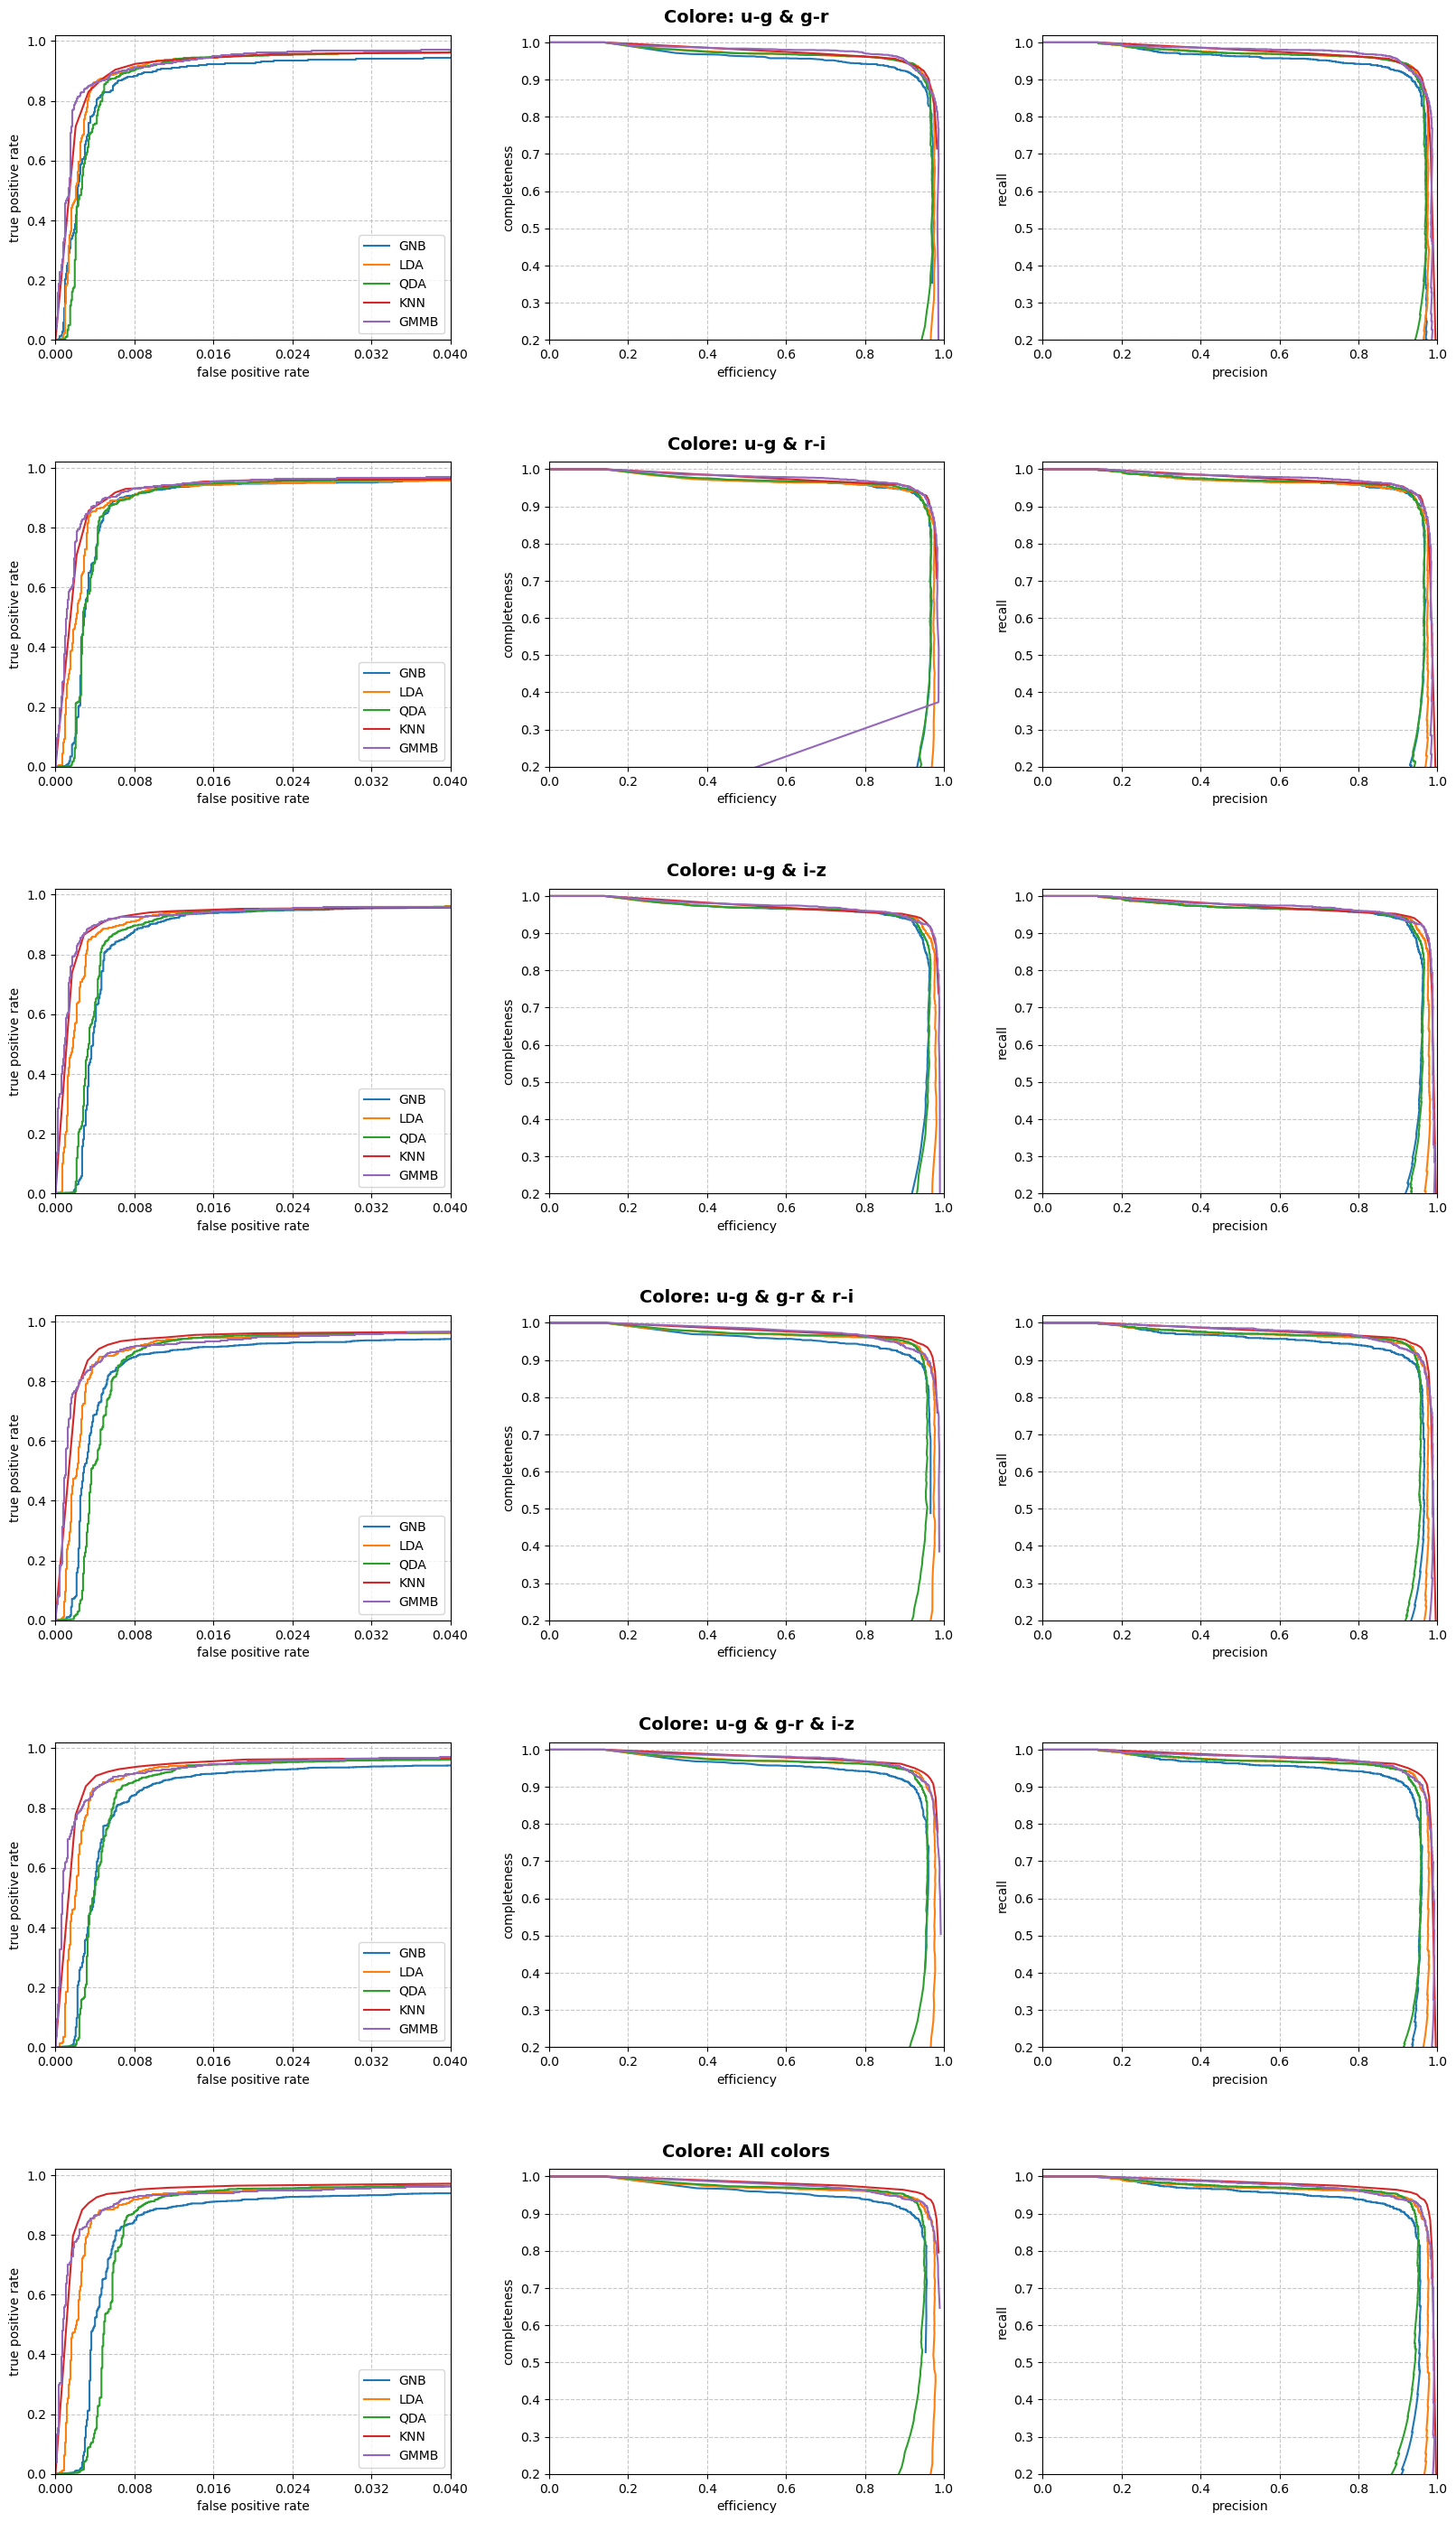

In [8]:
# Plot ROC curves and completeness/efficiency
fig, ax = plt.subplots(6, 3,figsize=(18, 36))

ax = ax.flatten()
fig.subplots_adjust(left=0.1, right=0.95, bottom=0.15, top=0.9, wspace=0.25, hspace=0.4)

thresholds = np.linspace(0, 1, 1001)[:-1]

# iterate through and show results
for i, col in enumerate(multi_col):
        
    ax1 = 3 * i
    ax2 = ax1 + 1
    ax3 = ax1 + 2
        
    for name, y_prob in zip(names, multi_col_probs[i]):
                
        fpr, tpr, thresh = roc_curve(y_test, y_prob)
        precision, recall, thresh2 = precision_recall_curve(y_test, y_prob)

        # add (0, 0) as first point
        fpr = np.concatenate([[0], fpr])
        tpr = np.concatenate([[0], tpr])
        # Here we add (1,0) 
        precision = np.concatenate([[0], precision])
        recall = np.concatenate([[1], recall])
        thresh2 = np.concatenate([[0], thresh2])

        ax[ax1].plot(fpr, tpr, label=labels[name])

        #See note above about astroML vs. sklearn
        #Note that the range of threshhold values here is 0% to 100% (0.0 to 1.0)
        comp = np.zeros_like(thresholds)
        cont = np.zeros_like(thresholds)
        for j, t in enumerate(thresholds):
            y_pred = (y_prob >= t)
            comp[j], cont[j] = completeness_contamination(y_pred, y_test)
        comp = np.concatenate([[1], comp])
        cont = np.concatenate([[1], cont])
        ax[ax2].plot(1 - cont, comp, label=labels[name])
        
        ax[ax3].plot(precision, recall, label=labels[name])

    ax[ax1].set_xlim(0, 0.04)
    ax[ax1].set_ylim(0, 1.02)
    ax[ax1].xaxis.set_major_locator(plt.MaxNLocator(5))
    ax[ax1].set_xlabel('false positive rate')
    ax[ax1].set_ylabel('true positive rate')
    ax[ax1].legend(loc=4)
    ax[ax1].grid(True, linestyle='--', alpha=0.7)

    ax[ax2].set_xlabel('efficiency')
    ax[ax2].set_ylabel('completeness')
    ax[ax2].set_xlim(0, 1.0)
    ax[ax2].set_ylim(0.2, 1.02)
    ax[ax2].set_title(f"Colore: {multi_label[i]}", fontsize=14, fontweight='bold', pad=10)
    ax[ax2].grid(True, linestyle='--', alpha=0.7)

    ax[ax3].set_xlabel('precision')
    ax[ax3].set_ylabel('recall')
    ax[ax3].set_xlim(0, 1.0)
    ax[ax3].set_ylim(0.2, 1.02)
    ax[ax3].grid(True, linestyle='--', alpha=0.7)
    

plt.show()

## PCA

In [9]:
k = 5 # number of neighbors
n = 4 # number of dimensions


means = df_quasar[["u-g", "g-r", "r-i", "i-z"]].mean().values
std = df_quasar[["u-g", "g-r", "r-i", "i-z"]].std().values

X_scaled = (X - means) / std

# 1. Initialize and Fit
pca = PCA(n_components=4)
# transform() gives you the new coordinates (Principal Components)
X_pca = pca.fit_transform(X_scaled) 

# 2. Access the variance (Eigenvalues)
eigenvalues = pca.explained_variance_

# 3. Access the directions (Eigenvectors)
eigenvectors = pca.components_

print(eigenvalues.shape)
print(eigenvectors.shape)
print(X_pca.shape)

(4,)
(4, 4)
(50000, 4)


In [11]:
comps = ["pca1", "pca2", "pca3", "pca4"]

(X_train_pca, X_test_pca), (y_train_pca, y_test_pca) = split_samples(X_pca, y, [0.75, 0.25],
                                                     random_state=0)

pca_probs = []
for i, comp in enumerate(comps):
    print(f"Processing column: {comps[i]}")
    set = [X_train_pca[:, i], y_train_pca[:], X_test_pca[:, i]]
    names, probs = compute_models(set, 
                                (GaussianNB, {}),
                                (LDA, {}),
                                (QDA, {}),
                                (KNeighborsClassifier, dict(n_neighbors=10)),
                                (GMMBayes, dict(n_components=3, tol=1E-5,
                                                covariance_type='full')))
    
    pca_probs.append(probs)
    

Processing column: pca1
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes
Processing column: pca2
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes


c:\Users\nicco\anaconda3\Lib\site-packages\sklearn\mixture\_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


Processing column: pca3
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes
Processing column: pca4
Processing classifier: GaussianNB
Processing classifier: LinearDiscriminantAnalysis
Processing classifier: QuadraticDiscriminantAnalysis
Processing classifier: KNeighborsClassifier
Processing classifier: GMMBayes


c:\Users\nicco\anaconda3\Lib\site-packages\sklearn\mixture\_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


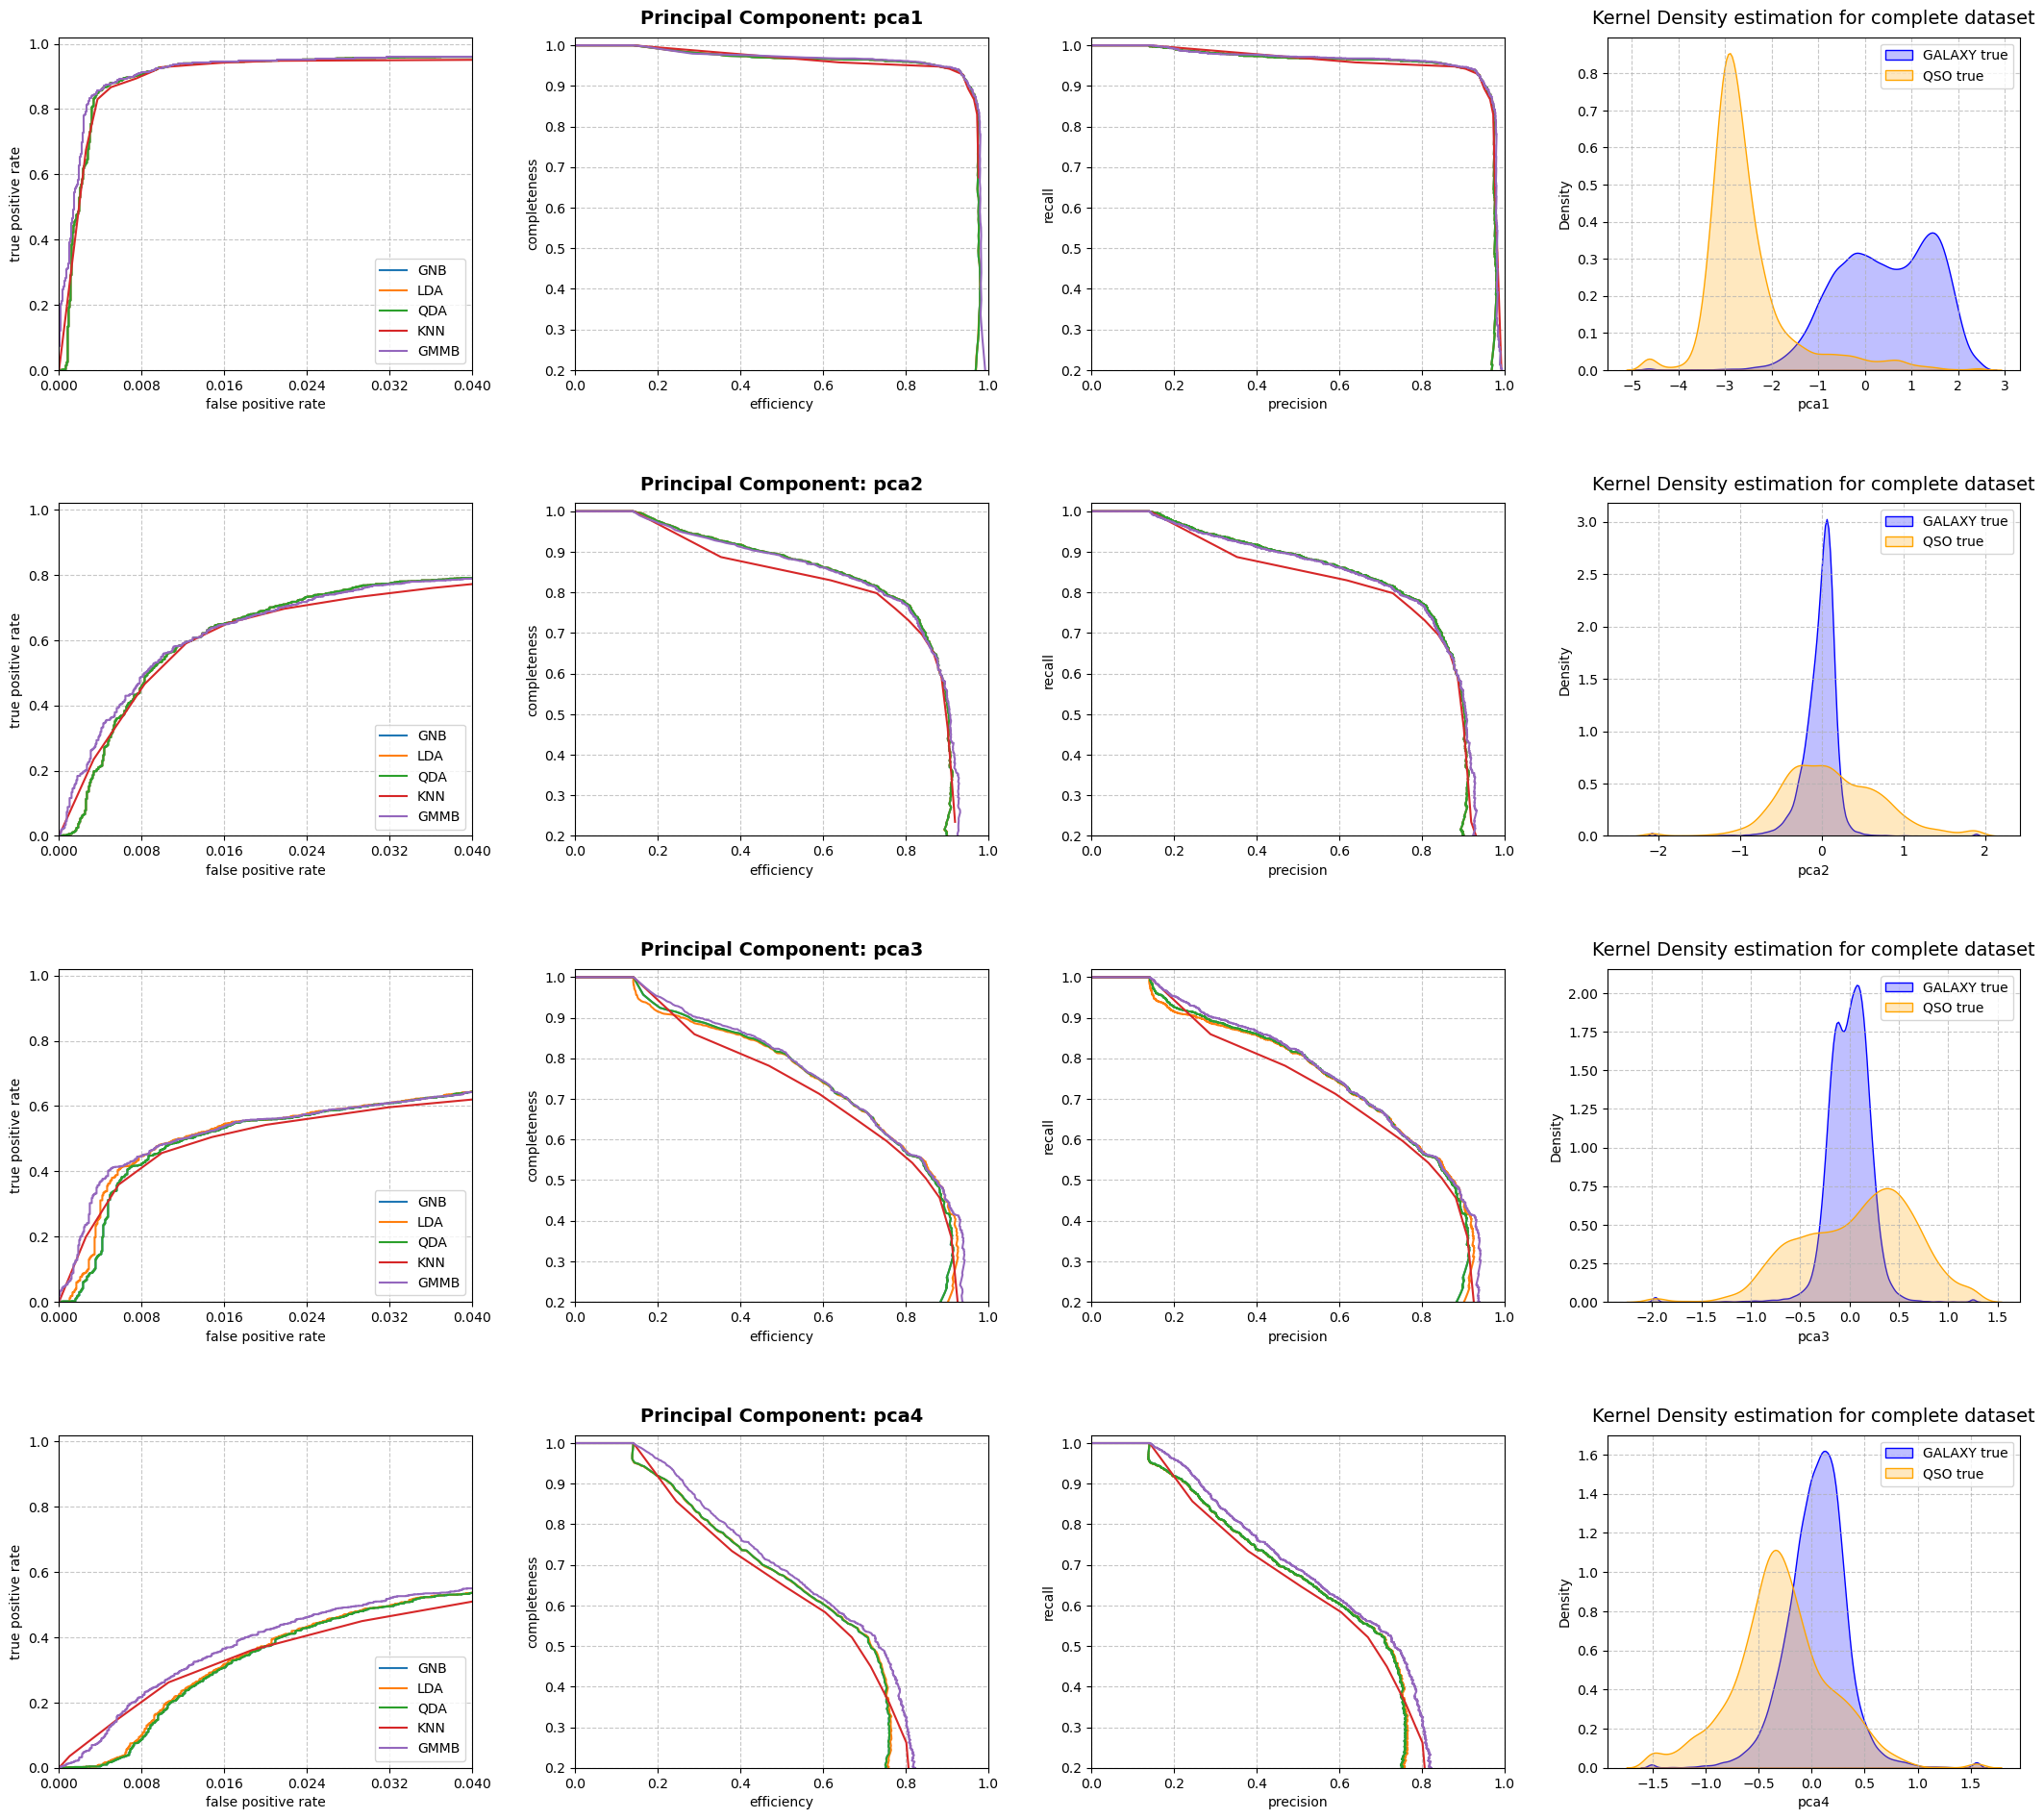

In [13]:
# Plot ROC curves and completeness/efficiency
fig, ax = plt.subplots(4, 4,figsize=(24, 24))

ax = ax.flatten()
fig.subplots_adjust(left=0.1, right=0.95, bottom=0.15, top=0.9, wspace=0.25, hspace=0.4)

# iterate through and show results
for i, component in enumerate(comps):
        
    ax1 = 4 * i
    ax2 = ax1 + 1
    ax3 = ax1 + 2
    ax4 = ax1 + 3
        
    for name, y_prob in zip(names, col_probs[i]):
                
        fpr, tpr, thresh = roc_curve(y_test, y_prob)
        precision, recall, thresh2 = precision_recall_curve(y_test, y_prob)

        # add (0, 0) as first point
        fpr = np.concatenate([[0], fpr])
        tpr = np.concatenate([[0], tpr])
        # Here we add (1,0) 
        precision = np.concatenate([[0], precision])
        recall = np.concatenate([[1], recall])
        thresh2 = np.concatenate([[0], thresh2])

        ax[ax1].plot(fpr, tpr, label=labels[name])

        #See note above about astroML vs. sklearn
        #Note that the range of threshhold values here is 0% to 100% (0.0 to 1.0)
        comp = np.zeros_like(thresholds)
        cont = np.zeros_like(thresholds)
        for j, t in enumerate(thresholds):
            y_pred = (y_prob >= t)
            comp[j], cont[j] = completeness_contamination(y_pred, y_test)
        comp = np.concatenate([[1], comp])
        cont = np.concatenate([[1], cont])
        ax[ax2].plot(1 - cont, comp, label=labels[name])
        
        ax[ax3].plot(precision, recall, label=labels[name])

    ax[ax1].set_xlim(0, 0.04)
    ax[ax1].set_ylim(0, 1.02)
    ax[ax1].xaxis.set_major_locator(plt.MaxNLocator(5))
    ax[ax1].set_xlabel('false positive rate')
    ax[ax1].set_ylabel('true positive rate')
    ax[ax1].legend(loc=4)
    ax[ax1].grid(True, linestyle='--', alpha=0.7)

    ax[ax2].set_xlabel('efficiency')
    ax[ax2].set_ylabel('completeness')
    ax[ax2].set_xlim(0, 1.0)
    ax[ax2].set_ylim(0.2, 1.02)
    ax[ax2].set_title(f"Principal Component: {component}", fontsize=14, fontweight='bold', pad=10)
    ax[ax2].grid(True, linestyle='--', alpha=0.7)

    ax[ax3].set_xlabel('precision')
    ax[ax3].set_ylabel('recall')
    ax[ax3].set_xlim(0, 1.0)
    ax[ax3].set_ylim(0.2, 1.02)
    ax[ax3].grid(True, linestyle='--', alpha=0.7)
    
    #I clip the data to avoid the influence of outliers in the KDE plot
    min_x = np.percentile(X_pca[:, i], 0.25)
    max_x = np.percentile(X_pca[:, i], 99.75)
    X_clipped = np.clip(X_pca[:, i], min_x, max_x)
    
    sns.kdeplot(X_clipped[y == 0], color='blue', ax = ax[ax4], label='GALAXY true', fill=True)
    sns.kdeplot(X_clipped[y == 1], color='orange', ax = ax[ax4], label='QSO true', fill=True)
    ax[ax4].set_title(f"Kernel Density estimation for complete dataset", fontsize=14, pad=10)
    ax[ax4].set_xlabel(f'{component}')
    ax[ax4].set_ylabel('Density')
    ax[ax4].grid(True, linestyle='--', alpha=0.7)
    ax[ax4].legend()  

plt.show()